In [3]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path



df = pd.read_csv("../data/processed/orders_prepared.csv")
route_summary = pd.read_csv("../data/processed/route_level_summary.csv")

print("PREPARED DATASET")
print("Shape:", df.shape)
print("Columns:", df.columns.tolist())
print("Route column exists:", "Route" in df.columns)

print("\nROUTE SUMMARY")
print("Shape:", route_summary.shape)
print("Columns:", route_summary.columns.tolist())
print("Route column exists:", "Route" in route_summary.columns)

display(df.head(3))
display(route_summary.head(3))


PREPARED DATASET
Shape: (10194, 36)
Columns: ['Row ID', 'Order ID', 'Order Date', 'Ship Date', 'Ship Mode', 'Customer ID', 'Country/Region', 'City', 'State/Province', 'Postal Code', 'Division', 'Region', 'Product ID', 'Product Name', 'Sales', 'Units', 'Gross Profit', 'Cost', 'Shipping Lead Time', 'Order ID Year', 'Order Year', 'Ship Year', 'LT Cluster', 'Cluster Min', 'Residual Days', 'Offset Step k', 'Candidate Ship Days (hypothesis)', 'Order Key', 'Is Canada', 'Gap After Year Shift (days)', 'Is Repeated Line', 'ID Prefix', 'Adjusted Lead Time', 'Factory', 'Factory Latitude', 'Factory Longitude']
Route column exists: False

ROUTE SUMMARY
Shape: (49, 9)
Columns: ['Route', 'Total_Shipments', 'Mean_Lead_Time', 'Median_Lead_Time', 'Std_Lead_Time', 'Min_Lead_Time', 'Max_Lead_Time', 'Lead_Time_Range', 'Lead_Time_CV_Percent']
Route column exists: True


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Country/Region,City,State/Province,Postal Code,...,Candidate Ship Days (hypothesis),Order Key,Is Canada,Gap After Year Shift (days),Is Repeated Line,ID Prefix,Adjusted Lead Time,Factory,Factory Latitude,Factory Longitude
0,1,US-2021-103800-CHO-MIL-31000,2024-01-03,2026-06-30,Standard Class,103800,United States,Houston,Texas,77095,...,5,US-2021-103800,False,179,False,CHO,179,Wicked Choccy's,32.076176,-81.088371
1,2,US-2021-112326-CHO-TRI-54000,2024-01-04,2026-07-01,Standard Class,112326,United States,Naperville,Illinois,60540,...,5,US-2021-112326,False,179,False,CHO,179,Wicked Choccy's,32.076176,-81.088371
2,3,US-2021-112326-CHO-NUT-13000,2024-01-04,2026-07-01,Standard Class,112326,United States,Naperville,Illinois,60540,...,5,US-2021-112326,False,179,False,CHO,179,Lot's O' Nuts,32.881893,-111.768036


,Route,Total_Shipments,Mean_Lead_Time,Median_Lead_Time,Std_Lead_Time,Min_Lead_Time,Max_Lead_Time,Lead_Time_Range,Lead_Time_CV_Percent
0,Lot's O' Nuts → United States → Atlantic → Con...,30,1420.55,1635.0,249.39,906,1641,735,17.56
1,Lot's O' Nuts → United States → Atlantic → Del...,32,1273.30,1272.0,251.92,906,1641,735,19.78
2,Lot's O' Nuts → United States → Atlantic → Mar...,31,1370.67,1274.0,221.92,908,1641,733,16.19


In [4]:

# 1. Standardize column names
df.columns = df.columns.str.strip()
route_summary.columns = route_summary.columns.str.strip()

# 2. Check required columns
required_df = ["Route", "Order Key", "Factory", "Shipping Lead Time"]
required_summary = [
    "Route",
    "Total_Shipments",
    "Mean_Lead_Time",
    "Median_Lead_Time",
    "Std_Lead_Time",
    "Lead_Time_CV_Percent"
]

missing_df = [col for col in required_df if col not in df.columns]
missing_summary = [
    col for col in required_summary if col not in route_summary.columns
]

print("Missing columns in prepared data:", missing_df)
print("Missing columns in route summary:", missing_summary)

if missing_df or missing_summary:
    print("\nPlease fix the missing columns before continuing.")
else:
    print("\nBoth datasets contain the required columns.")

    df["Shipping Lead Time"] = pd.to_numeric(
        df["Shipping Lead Time"], errors="coerce"
    )

    print("Prepared data shape:", df.shape)
    print("Route summary shape:", route_summary.shape)
    print("Unique routes:", df["Route"].nunique())
    print("Eligible routes:", len(route_summary))
    print(
        "Missing shipping lead times:",
        df["Shipping Lead Time"].isna().sum()
    )


Missing columns in prepared data: ['Route']
Missing columns in route summary: []

Please fix the missing columns before continuing.


In [5]:

# Rank eligible routes by average lead time

ranked_routes = route_summary.copy()

ranked_routes = ranked_routes.sort_values(
    by="Mean_Lead_Time",
    ascending=True
).reset_index(drop=True)

ranked_routes.insert(
    0,
    "Efficiency_Rank",
    range(1, len(ranked_routes) + 1)
)

print("Total eligible routes ranked:", len(ranked_routes))
print("\nTop 10 routes by lowest average lead time:")
display(ranked_routes.head(10))

print("\nBottom 10 routes by highest average lead time:")
display(ranked_routes.tail(10).sort_values(
    "Mean_Lead_Time",
    ascending=False
))


Total eligible routes ranked: 49

Top 10 routes by lowest average lead time:


,Efficiency_Rank,Route,Total_Shipments,Mean_Lead_Time,Median_Lead_Time,Std_Lead_Time,Min_Lead_Time,Max_Lead_Time,Lead_Time_Range,Lead_Time_CV_Percent
0,1,Lot's O' Nuts → United States → Gulf → Virginia,75,1229.49,1273.0,262.01,905,1641,736,21.31
1,2,Wicked Choccy's → United States → Gulf → Virginia,72,1238.88,1273.0,254.77,904,1642,738,20.56
2,3,Lot's O' Nuts → United States → Pacific → Oregon,46,1245.19,1273.0,269.88,906,1642,736,21.67
3,4,Lot's O' Nuts → United States → Atlantic → Del...,32,1273.30,1272.0,251.92,906,1641,735,19.78
4,5,Wicked Choccy's → United States → Atlantic → D...,30,1273.71,1274.0,210.88,906,1641,735,16.56
5,6,Wicked Choccy's → United States → Interior → M...,70,1291.85,1273.5,239.86,906,1642,736,18.57
6,7,Lot's O' Nuts → United States → Atlantic → Mas...,47,1292.12,1273.0,252.38,906,1641,735,19.53
7,8,Lot's O' Nuts → United States → Interior → Mic...,93,1303.01,1273.0,247.20,906,1642,736,18.97
8,9,Wicked Choccy's → United States → Gulf → Florida,111,1305.09,1273.0,250.27,904,1642,738,19.18
9,10,Lot's O' Nuts → United States → Pacific → Arizona,77,1306.20,1274.0,253.90,904,1642,738,19.44



Bottom 10 routes by highest average lead time:


,Efficiency_Rank,Route,Total_Shipments,Mean_Lead_Time,Median_Lead_Time,Std_Lead_Time,Min_Lead_Time,Max_Lead_Time,Lead_Time_Range,Lead_Time_CV_Percent
48,49,Lot's O' Nuts → United States → Atlantic → Con...,30,1420.55,1635.0,249.39,906,1641,735,17.56
47,48,Wicked Choccy's → United States → Interior → I...,40,1402.46,1275.5,257.77,904,1642,738,18.38
46,47,Wicked Choccy's → United States → Gulf → Tenne...,47,1393.76,1276.0,241.36,908,1641,733,17.32
45,46,Lot's O' Nuts → United States → Gulf → Tennessee,69,1390.96,1276.0,257.72,906,1642,736,18.53
44,45,Wicked Choccy's → United States → Pacific → Wa...,159,1375.72,1276.0,270.80,904,1642,738,19.68
43,44,Lot's O' Nuts → United States → Atlantic → Mar...,31,1370.67,1274.0,221.92,908,1641,733,16.19
42,43,Lot's O' Nuts → United States → Interior → Wis...,35,1367.64,1274.0,242.38,906,1641,735,17.72
41,42,Lot's O' Nuts → United States → Interior → Ind...,54,1366.79,1274.0,236.12,907,1642,735,17.28
40,41,Wicked Choccy's → United States → Gulf → North...,79,1352.76,1274.0,261.44,904,1642,738,19.33
39,40,Lot's O' Nuts → United States → Interior → Min...,34,1350.40,1274.0,282.63,906,1642,736,20.93


In [6]:

# Top 10 routes with the lowest recorded lead times
top_10_routes = ranked_routes.nsmallest(
    10, "Mean_Lead_Time"
).copy()

# Bottom 10 routes with the highest recorded lead times
bottom_10_routes = ranked_routes.nlargest(
    10, "Mean_Lead_Time"
).copy()

top_10_routes["Benchmark_Group"] = "Top 10 - Lowest Lead Time"
bottom_10_routes["Benchmark_Group"] = "Bottom 10 - Highest Lead Time"

benchmark_comparison = pd.concat(
    [top_10_routes, bottom_10_routes],
    ignore_index=True
)

comparison_columns = [
    "Benchmark_Group",
    "Route",
    "Total_Shipments",
    "Mean_Lead_Time",
    "Median_Lead_Time",
    "Std_Lead_Time",
    "Lead_Time_CV_Percent"
]

display(
    benchmark_comparison[comparison_columns]
    .sort_values(
        ["Benchmark_Group", "Mean_Lead_Time"],
        ascending=[True, True]
    )
    .reset_index(drop=True)
)

# Compare group averages
group_comparison = benchmark_comparison.groupby(
    "Benchmark_Group"
).agg(
    Route_Count=("Route", "nunique"),
    Average_Lead_Time=("Mean_Lead_Time", "mean"),
    Average_Shipments=("Total_Shipments", "mean")
).round(2)

display(group_comparison)


,Benchmark_Group,Route,Total_Shipments,Mean_Lead_Time,Median_Lead_Time,Std_Lead_Time,Lead_Time_CV_Percent
0,Bottom 10 - Highest Lead Time,Lot's O' Nuts → United States → Interior → Min...,34,1350.40,1274.0,282.63,20.93
1,Bottom 10 - Highest Lead Time,Wicked Choccy's → United States → Gulf → North...,79,1352.76,1274.0,261.44,19.33
2,Bottom 10 - Highest Lead Time,Lot's O' Nuts → United States → Interior → Ind...,54,1366.79,1274.0,236.12,17.28
3,Bottom 10 - Highest Lead Time,Lot's O' Nuts → United States → Interior → Wis...,35,1367.64,1274.0,242.38,17.72
4,Bottom 10 - Highest Lead Time,Lot's O' Nuts → United States → Atlantic → Mar...,31,1370.67,1274.0,221.92,16.19
5,Bottom 10 - Highest Lead Time,Wicked Choccy's → United States → Pacific → Wa...,159,1375.72,1276.0,270.80,19.68
6,Bottom 10 - Highest Lead Time,Lot's O' Nuts → United States → Gulf → Tennessee,69,1390.96,1276.0,257.72,18.53
7,Bottom 10 - Highest Lead Time,Wicked Choccy's → United States → Gulf → Tenne...,47,1393.76,1276.0,241.36,17.32
8,Bottom 10 - Highest Lead Time,Wicked Choccy's → United States → Interior → I...,40,1402.46,1275.5,257.77,18.38
9,Bottom 10 - Highest Lead Time,Lot's O' Nuts → United States → Atlantic → Con...,30,1420.55,1635.0,249.39,17.56


,Route_Count,Average_Lead_Time,Average_Shipments
Benchmark_Group,,,
Bottom 10 - Highest Lead Time,10,1379.17,57.8
Top 10 - Lowest Lead Time,10,1275.88,65.3


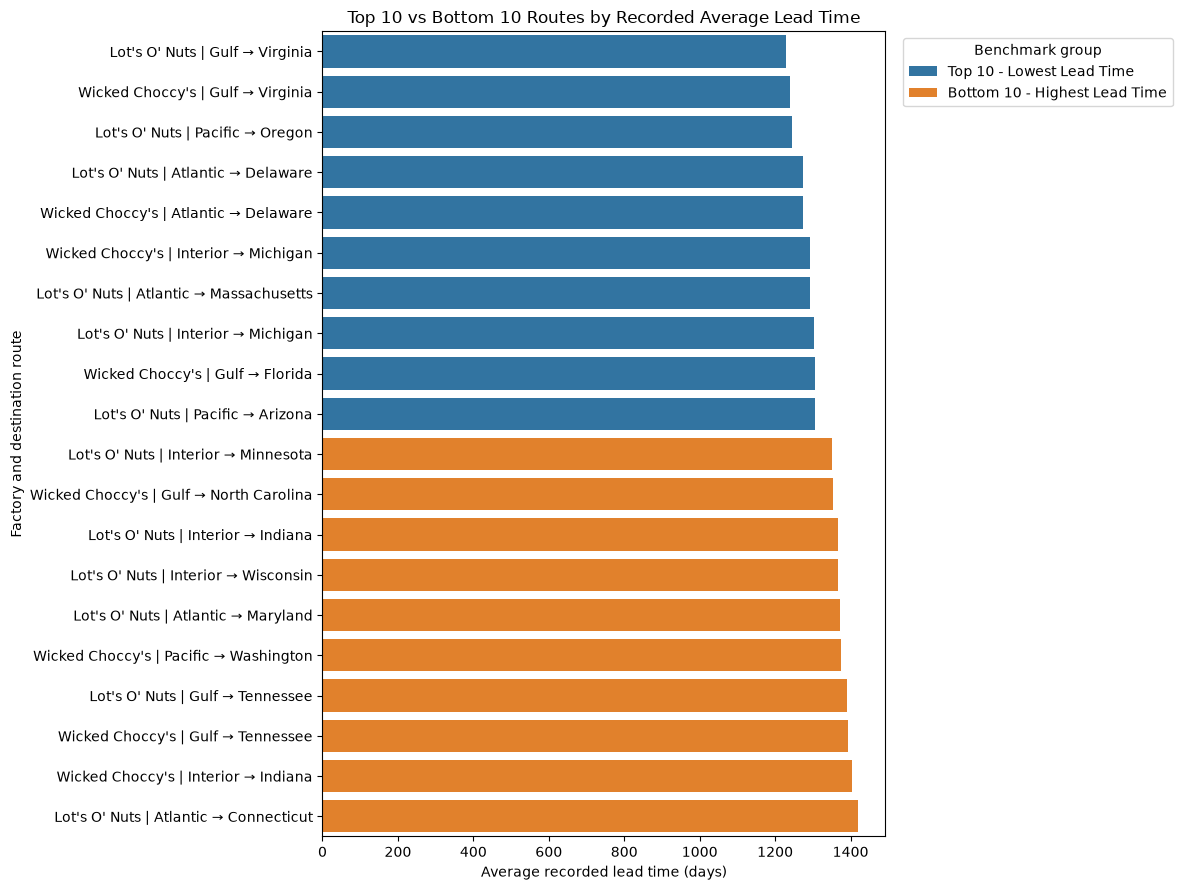

In [7]:

import matplotlib.pyplot as plt
import seaborn as sns

# Prepare data for plotting
plot_data = benchmark_comparison.copy()

plot_data["Route_Short"] = (
    plot_data["Route"]
    .str.replace(" → United States → ", " | ", regex=False)
)

plot_data = plot_data.sort_values("Mean_Lead_Time")

plt.figure(figsize=(12, 9))

sns.barplot(
    data=plot_data,
    x="Mean_Lead_Time",
    y="Route_Short",
    hue="Benchmark_Group",
    dodge=False
)

plt.title("Top 10 vs Bottom 10 Routes by Recorded Average Lead Time")
plt.xlabel("Average recorded lead time (days)")
plt.ylabel("Factory and destination route")
plt.legend(title="Benchmark group", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()


In [8]:

# Compare recorded lead-time performance across shipping modes

ship_mode_summary = (
    df.groupby("Ship Mode")
    .agg(
        Total_Shipments=("Order Key", "nunique"),
        Mean_Lead_Time=("Shipping Lead Time", "mean"),
        Median_Lead_Time=("Shipping Lead Time", "median"),
        Std_Lead_Time=("Shipping Lead Time", "std")
    )
    .reset_index()
)

ship_mode_summary["Lead_Time_CV_Percent"] = (
    ship_mode_summary["Std_Lead_Time"]
    / ship_mode_summary["Mean_Lead_Time"].replace(0, np.nan)
) * 100

numeric_cols = ship_mode_summary.select_dtypes(
    include="number"
).columns

ship_mode_summary[numeric_cols] = (
    ship_mode_summary[numeric_cols].round(2)
)

# Display modes from lowest to highest average recorded lead time
ship_mode_summary = ship_mode_summary.sort_values(
    "Mean_Lead_Time",
    ascending=True
).reset_index(drop=True)

display(ship_mode_summary)


,Ship Mode,Total_Shipments,Mean_Lead_Time,Median_Lead_Time,Std_Lead_Time,Lead_Time_CV_Percent
0,Standard Class,3068,1314.33,1274.0,262.40,19.96
1,Second Class,982,1323.85,1273.0,261.81,19.78
2,Same Day,266,1333.44,1269.0,253.81,19.03
3,First Class,795,1338.28,1272.0,265.63,19.85


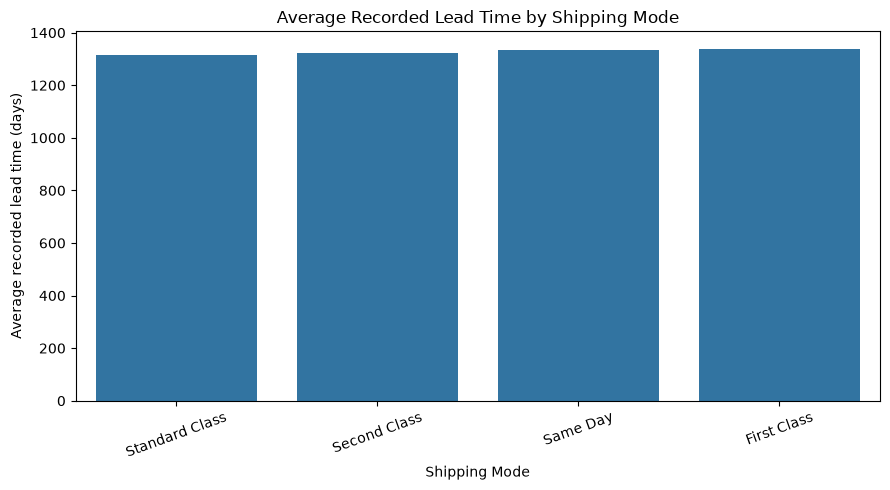

In [9]:

plt.figure(figsize=(9, 5))

sns.barplot(
    data=ship_mode_summary,
    x="Ship Mode",
    y="Mean_Lead_Time"
)

plt.title("Average Recorded Lead Time by Shipping Mode")
plt.xlabel("Shipping Mode")
plt.ylabel("Average recorded lead time (days)")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()


In [10]:

# Rank ship modes by recorded average lead time
ship_mode_ranking = ship_mode_summary.copy()

ship_mode_ranking["Recorded_Lead_Time_Rank"] = (
    ship_mode_ranking["Mean_Lead_Time"]
    .rank(method="min", ascending=True)
    .astype(int)
)

ship_mode_ranking = ship_mode_ranking[
    [
        "Recorded_Lead_Time_Rank",
        "Ship Mode",
        "Total_Shipments",
        "Mean_Lead_Time",
        "Median_Lead_Time",
        "Std_Lead_Time",
        "Lead_Time_CV_Percent"
    ]
].sort_values("Recorded_Lead_Time_Rank")

display(ship_mode_ranking)

print("\nExploratory observations:")
print(
    "Lowest recorded mean lead time:",
    ship_mode_ranking.iloc[0]["Ship Mode"]
)
print(
    "Highest recorded mean lead time:",
    ship_mode_ranking.iloc[-1]["Ship Mode"]
)
print(
    "Difference between highest and lowest recorded means:",
    round(
        ship_mode_ranking["Mean_Lead_Time"].max()
        - ship_mode_ranking["Mean_Lead_Time"].min(),
        2
    ),
    "days"
)


,Recorded_Lead_Time_Rank,Ship Mode,Total_Shipments,Mean_Lead_Time,Median_Lead_Time,Std_Lead_Time,Lead_Time_CV_Percent
0,1,Standard Class,3068,1314.33,1274.0,262.40,19.96
1,2,Second Class,982,1323.85,1273.0,261.81,19.78
2,3,Same Day,266,1333.44,1269.0,253.81,19.03
3,4,First Class,795,1338.28,1272.0,265.63,19.85



Exploratory observations:
Lowest recorded mean lead time: Standard Class
Highest recorded mean lead time: First Class
Difference between highest and lowest recorded means: 23.95 days



## Efficiency Benchmarking Summary

The efficiency benchmarking analysis evaluated 49 eligible shipping routes with at least 30 shipments, ranking them by average recorded lead time and identifying the top 10 and bottom 10 routes for comparative analysis. Route-level metrics included shipment volume, mean and median lead time, standard deviation, lead-time range, and coefficient of variation. Shipping performance was also compared across Standard Class, Second Class, Same Day, and First Class. Standard Class recorded the lowest average lead time (1,314.33 days) across 3,068 shipments, while First Class recorded the highest (1,338.28 days), a difference of 23.95 days. However, the unusually large recorded lead times require validation of the source dates before these findings can be interpreted as actual delivery-efficiency results.
